<a href="https://colab.research.google.com/github/afrateitba/TP-PSI-G8/blob/karo_03/03_mejoramiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Etapa 3 — Mejoramiento y restauración

## Objetivo

Evaluar si el procesamiento de los mapas permite mejorar la
separación entre vasos y fondo respecto de sus versiones originales.

Se comienza con PC3 como candidata principal y el canal verde
como referencia, según los resultados exploratorios de la etapa 2.

## Primer experimento: corrección del fondo

La iluminación de la retina no es uniforme. Se estimará un fondo
suave y se restará del mapa para destacar diferencias locales.

Se comparará cada mapa sin corrección contra su versión corregida,
manteniendo el sentido elegido: vasos claros para PC3 y oscuros
para verde. La corrección puede ayudar o perjudicar; se evaluará
con AUC dentro del campo de visión de referencia.

Primero se comprobará el procedimiento en una imagen de desarrollo.
Los tamaños de suavizado y el criterio de comparación se definirán
antes de ejecutar el experimento completo.

Solo se utilizarán imágenes de desarrollo. Esta etapa todavía
no genera la máscara final de vasos.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import os
import sys

ROOT = Path("/content/drive/MyDrive/TP-PSI-G8-main")

assert (ROOT / "src").is_dir(), (
    "No encuentro el proyecto. Revisá la ruta."
)

os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%pip install -q -r requirements.txt

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import ndimage as ndi

from src.color import crear_mapas
from src.data import dev_ids, load_image, load_vessels, load_fov
from src.fov import detect_fov_robust, fov_diameter

image_id = dev_ids()[0]

rgb = load_image(image_id)
vasos = load_vessels(image_id)
campo = load_fov(image_id)

mapas = crear_mapas(rgb)

# Orientamos ambos mapas para que un valor alto indique vaso.
# Esto facilita aplicar y evaluar los mismos procedimientos.
puntuaciones = {
    "PC3": mapas["PC3"],
    "Verde": -mapas["Verde"]
}

# La corrección utiliza solo la retina detectada automáticamente.
campo_auto = detect_fov_robust(rgb)

print("Imagen cargada:", image_id)

Imagen cargada: 01_h


In [ ]:
def corregir_fondo(mapa, region, sigma):
    """Resta un fondo gaussiano estimado dentro de la retina."""

    mapa = mapa.astype(np.float32)
    mascara = region.astype(np.float32)

    # Suavizado normalizado para evitar que el exterior negro
    # arrastre artificialmente la estimación del borde.
    numerador = ndi.gaussian_filter(
        np.where(region, mapa, 0.0),
        sigma=sigma,
        mode="constant",
        cval=0.0
    )

    denominador = ndi.gaussian_filter(
        mascara,
        sigma=sigma,
        mode="constant",
        cval=0.0
    )

    fondo = np.divide(
        numerador,
        denominador,
        out=np.zeros_like(numerador),
        where=denominador > 1e-6
    )

    corregido = mapa - fondo

    return fondo, corregido


fraccion_sigma = 0.02
sigma = fraccion_sigma * fov_diameter(campo_auto)

fondos = {}
corregidos = {}

for nombre, mapa in puntuaciones.items():
    fondos[nombre], corregidos[nombre] = corregir_fondo(
        mapa,
        campo_auto,
        sigma
    )

print(f"Sigma exploratorio: {sigma:.1f} píxeles")

Sigma exploratorio: 65.3 píxeles


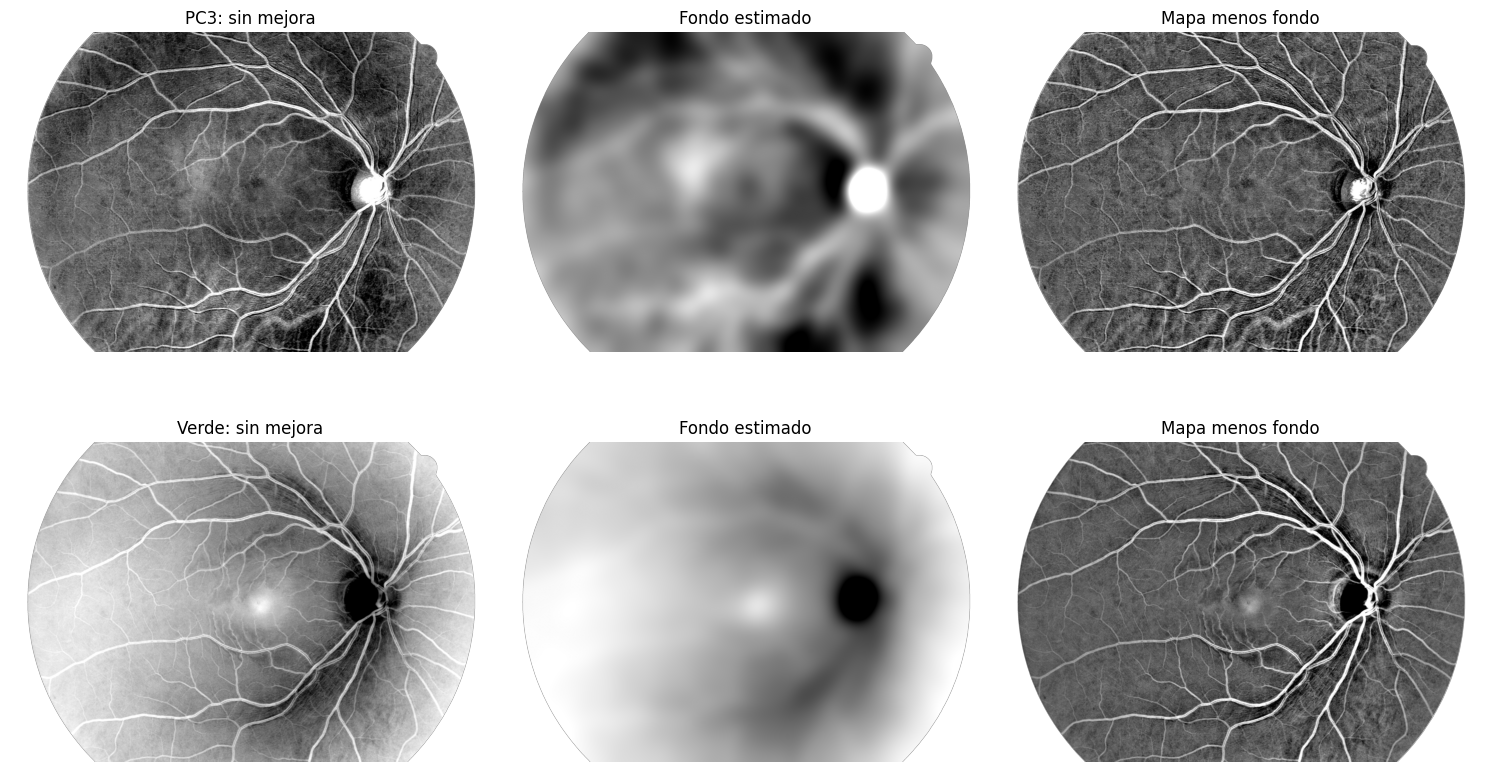

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 9))

for fila, nombre in enumerate(puntuaciones):

    versiones = [
        puntuaciones[nombre],
        fondos[nombre],
        corregidos[nombre]
    ]

    titulos = [
        f"{nombre}: sin mejora",
        "Fondo estimado",
        "Mapa menos fondo"
    ]

    for eje, mapa, titulo in zip(ax[fila], versiones, titulos):

        minimo, maximo = np.percentile(
            mapa[campo_auto], [1, 99]
        )

        visible = np.ma.masked_where(~campo_auto, mapa)

        eje.imshow(
            visible,
            cmap="gray",
            vmin=minimo,
            vmax=maximo
        )
        eje.set_title(titulo)
        eje.set_facecolor("black")
        eje.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from src.config import WIDTH_LIMITS_PX
from src.vessels import skeleton_widths, width_map

# Medimos el grosor en la referencia del experto
vasos_dentro = vasos & campo

esqueleto, anchos = skeleton_widths(vasos_dentro)
mapa_anchos = width_map(
    vasos_dentro,
    esqueleto,
    anchos
)

# Usamos el límite ya fijado en la etapa 1
finos = vasos_dentro & (mapa_anchos <= WIDTH_LIMITS_PX[0])
fondo_referencia = campo & ~vasos

# Para evaluar finos, excluimos los vasos medianos y gruesos
region_finos = finos | fondo_referencia

print("Píxeles de vasos finos:", int(finos.sum()))

Píxeles de vasos finos: 83799


In [ ]:
from scipy.stats import rankdata

def auc_puntuacion(puntuacion, referencia, region):
    """AUC considerando que un valor mayor indica vaso."""

    etiquetas = referencia[region].astype(bool)
    valores = puntuacion[region].astype(np.float64)

    positivos = int(etiquetas.sum())
    negativos = int((~etiquetas).sum())

    if positivos == 0 or negativos == 0:
        raise ValueError("Se necesitan vasos y fondo para calcular AUC.")

    rangos = rankdata(valores, method="average")

    return float(
        (rangos[etiquetas].sum()
         - positivos * (positivos + 1) / 2)
        / (positivos * negativos)
    )


filas = []

for nombre in puntuaciones:
    versiones = {
        "Sin mejora": puntuaciones[nombre],
        "Corrección del fondo": corregidos[nombre]
    }

    for version, mapa in versiones.items():
        filas.append({
            "Mapa": nombre,
            "Versión": version,
            "AUC todos": auc_puntuacion(
                mapa, vasos, campo
            ),
            "AUC finos": auc_puntuacion(
                mapa, vasos, region_finos
            )
        })

comparacion_fondo = pd.DataFrame(filas)

display(comparacion_fondo.round(4))

,Mapa,Versión,AUC todos,AUC finos
0,PC3,Sin mejora,0.8414,0.5983
1,PC3,Corrección del fondo,0.8544,0.6852
2,Verde,Sin mejora,0.6787,0.5571
3,Verde,Corrección del fondo,0.9352,0.8146


In [ ]:
from src.config import RESULTS_DIR, WIDTH_LIMITS_PX
from src.vessels import skeleton_widths, width_map

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
archivo = RESULTS_DIR / "03_correccion_fondo.csv"

resultados = []
ids_desarrollo = dev_ids()

for numero, identificador in enumerate(ids_desarrollo, start=1):

    # Fotografía y referencias
    foto = load_image(identificador)
    referencia = load_vessels(identificador)
    region = load_fov(identificador)

    # Identificamos vasos finos para evaluar
    vasos_region = referencia & region
    esq, anchos = skeleton_widths(vasos_region)
    grosores = width_map(vasos_region, esq, anchos)

    finos = vasos_region & (grosores <= WIDTH_LIMITS_PX[0])
    region_finos = finos | (region & ~referencia)

    # Creamos los mapas sin usar las referencias
    mapas_actuales = crear_mapas(foto)
    region_auto = detect_fov_robust(foto)
    sigma_actual = 0.02 * fov_diameter(region_auto)

    puntuaciones_actuales = {
        "PC3": mapas_actuales["PC3"],
        "Verde": -mapas_actuales["Verde"]
    }

    for nombre, original in puntuaciones_actuales.items():

        _, corregido = corregir_fondo(
            original, region_auto, sigma_actual
        )

        for version, mapa in {
            "Sin mejora": original,
            "Corrección del fondo": corregido
        }.items():

            resultados.append({
                "Imagen": identificador,
                "Mapa": nombre,
                "Versión": version,
                "Sigma": sigma_actual,
                "AUC todos": auc_puntuacion(
                    mapa, referencia, region
                ),
                "AUC finos": auc_puntuacion(
                    mapa, referencia, region_finos
                )
            })

    # Guardamos los resultados después de cada imagen
    resultados_fondo = pd.DataFrame(resultados)
    resultados_fondo.to_csv(archivo, index=False)

    print(
        f"{numero}/{len(ids_desarrollo)} terminada: {identificador}",
        flush=True
    )

print("\nComparación terminada.")

resumen_fondo = (
    resultados_fondo
    .groupby(["Mapa", "Versión"])[["AUC todos", "AUC finos"]]
    .mean()
    .reset_index()
)

display(resumen_fondo.round(4))

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g

Comparación terminada.


,Mapa,Versión,AUC todos,AUC finos
0,PC3,Corrección del fondo,0.8451,0.6687
1,PC3,Sin mejora,0.8115,0.6204
2,Verde,Corrección del fondo,0.9354,0.8129
3,Verde,Sin mejora,0.6894,0.5731


## Ecualización adaptativa del histograma — CLAHE

Se evalúa si mejorar el contraste local ayuda a separar vasos y fondo.

Se aplica CLAHE a PC3 y al verde orientado como puntuación de vaso.
Se compara contra los mapas sin mejora, usando AUC en todos los
vasos y en los finos.

Como candidata inicial se usan ventanas de aproximadamente un octavo
del diámetro del campo de visión y clip_limit = 0.01.
Son parámetros exploratorios, no valores definitivos.

El procesamiento utiliza el campo detectado automáticamente.
Las máscaras del experto se reservan para evaluar.

In [ ]:
from skimage.exposure import equalize_adapthist

def aplicar_clahe(mapa, region_auto):
    """Mejora el contraste local dentro de la retina."""

    valores = mapa[region_auto]
    minimo = float(valores.min())
    maximo = float(valores.max())

    if maximo == minimo:
        return np.zeros_like(mapa, dtype=np.float32)

    # CLAHE necesita intensidades entre 0 y 1
    normalizado = np.clip(
        (mapa.astype(np.float32) - minimo) / (maximo - minimo),
        0, 1
    )

    # Extendemos los valores del borde hacia el exterior,
    # para que el negro de afuera no domine las ventanas.
    indices = ndi.distance_transform_edt(
        ~region_auto,
        return_distances=False,
        return_indices=True
    )
    extendido = normalizado[tuple(indices)]

    tamano = max(2, round(fov_diameter(region_auto) / 8))

    return equalize_adapthist(
        extendido,
        kernel_size=(tamano, tamano),
        clip_limit=0.01
    ).astype(np.float32)

In [ ]:
ejemplo_id = dev_ids()[0]

foto_ej = load_image(ejemplo_id)
ref_ej = load_vessels(ejemplo_id)
campo_ej = load_fov(ejemplo_id)
auto_ej = detect_fov_robust(foto_ej)

mapas_ej = crear_mapas(foto_ej)

originales_ej = {
    "PC3": mapas_ej["PC3"],
    "Verde": -mapas_ej["Verde"]
}

# Región para evaluar vasos finos contra fondo
v_ej = ref_ej & campo_ej
esq_ej, anchos_ej = skeleton_widths(v_ej)
grosores_ej = width_map(v_ej, esq_ej, anchos_ej)

finos_ej = v_ej & (grosores_ej <= WIDTH_LIMITS_PX[0])
region_finos_ej = finos_ej | (campo_ej & ~ref_ej)

clahe_ej = {}
filas_clahe = []

for nombre, original in originales_ej.items():

    clahe_ej[nombre] = aplicar_clahe(original, auto_ej)

    for version, mapa in {
        "Sin mejora": original,
        "CLAHE": clahe_ej[nombre]
    }.items():

        filas_clahe.append({
            "Imagen": ejemplo_id,
            "Mapa": nombre,
            "Versión": version,
            "AUC todos": auc_puntuacion(
                mapa, ref_ej, campo_ej
            ),
            "AUC finos": auc_puntuacion(
                mapa, ref_ej, region_finos_ej
            )
        })

display(pd.DataFrame(filas_clahe).round(4))

,Imagen,Mapa,Versión,AUC todos,AUC finos
0,01_h,PC3,Sin mejora,0.8414,0.5983
1,01_h,PC3,CLAHE,0.8526,0.6360
2,01_h,Verde,Sin mejora,0.6787,0.5571
3,01_h,Verde,CLAHE,0.8339,0.6392


In [ ]:
from src.config import RESULTS_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
archivo_clahe = RESULTS_DIR / "03_clahe.csv"

resultados_clahe = []
ids_desarrollo = dev_ids()

for numero, identificador in enumerate(ids_desarrollo, start=1):

    foto = load_image(identificador)
    referencia = load_vessels(identificador)
    region = load_fov(identificador)
    region_auto = detect_fov_robust(foto)

    # Identificamos vasos finos para evaluar
    v = referencia & region
    esq, anchos = skeleton_widths(v)
    grosores = width_map(v, esq, anchos)

    finos = v & (grosores <= WIDTH_LIMITS_PX[0])
    region_finos = finos | (region & ~referencia)

    mapas_actuales = crear_mapas(foto)

    puntuaciones_actuales = {
        "PC3": mapas_actuales["PC3"],
        "Verde": -mapas_actuales["Verde"]
    }

    for nombre, original in puntuaciones_actuales.items():

        procesado = aplicar_clahe(original, region_auto)

        for version, mapa in {
            "Sin mejora": original,
            "CLAHE": procesado
        }.items():

            resultados_clahe.append({
                "Imagen": identificador,
                "Mapa": nombre,
                "Versión": version,
                "AUC todos": auc_puntuacion(
                    mapa, referencia, region
                ),
                "AUC finos": auc_puntuacion(
                    mapa, referencia, region_finos
                )
            })

    tabla_clahe = pd.DataFrame(resultados_clahe)
    tabla_clahe.to_csv(archivo_clahe, index=False)

    print(
        f"{numero}/{len(ids_desarrollo)} terminada: {identificador}",
        flush=True
    )

resumen_clahe = (
    tabla_clahe
    .groupby(["Mapa", "Versión"])[["AUC todos", "AUC finos"]]
    .mean()
    .reset_index()
)

display(resumen_clahe.round(4))

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Mapa,Versión,AUC todos,AUC finos
0,PC3,CLAHE,0.8381,0.6399
1,PC3,Sin mejora,0.8115,0.6204
2,Verde,CLAHE,0.8096,0.6419
3,Verde,Sin mejora,0.6894,0.5731


## Filtro homomórfico

Se prueba una candidata que reduce las variaciones amplias del
fondo y refuerza los detalles del mapa.

Los mapas se normalizan a valores positivos antes del logaritmo.
Se usa una escala de suavizado de 0.02 veces el diámetro del campo,
peso del fondo de 0.5 y peso del detalle de 1.5.

Estos valores definen una candidata exploratoria. Se compara
contra la versión sin mejora, sin combinarla todavía con CLAHE.

In [ ]:
def aplicar_homomorfico(mapa, region_auto):
    """Reduce el fondo suave y refuerza los detalles en escala log."""

    valores = mapa[region_auto]
    minimo = float(valores.min())
    maximo = float(valores.max())

    if maximo == minimo:
        return np.zeros_like(mapa, dtype=np.float32)

    normalizado = np.clip(
        (mapa.astype(np.float32) - minimo) / (maximo - minimo),
        0, 1
    )

    # Evitamos calcular logaritmo de cero
    log_mapa = np.log(normalizado + 0.001)

    sigma = 0.02 * fov_diameter(region_auto)

    # Reutilizamos la estimación de fondo dentro de la retina
    fondo_log, detalle_log = corregir_fondo(
        log_mapa, region_auto, sigma
    )

    log_filtrado = 0.5 * fondo_log + 1.5 * detalle_log

    return np.exp(log_filtrado).astype(np.float32)

In [ ]:
ejemplo_id = dev_ids()[0]

foto_ej = load_image(ejemplo_id)
ref_ej = load_vessels(ejemplo_id)
campo_ej = load_fov(ejemplo_id)
auto_ej = detect_fov_robust(foto_ej)

mapas_ej = crear_mapas(foto_ej)

originales_ej = {
    "PC3": mapas_ej["PC3"],
    "Verde": -mapas_ej["Verde"]
}

v_ej = ref_ej & campo_ej
esq_ej, anchos_ej = skeleton_widths(v_ej)
grosores_ej = width_map(v_ej, esq_ej, anchos_ej)

finos_ej = v_ej & (grosores_ej <= WIDTH_LIMITS_PX[0])
region_finos_ej = finos_ej | (campo_ej & ~ref_ej)

homomorficos_ej = {}
filas_homomorfico = []

for nombre, original in originales_ej.items():

    procesado = aplicar_homomorfico(original, auto_ej)
    homomorficos_ej[nombre] = procesado

    for version, mapa in {
        "Sin mejora": original,
        "Homomórfico": procesado
    }.items():

        filas_homomorfico.append({
            "Imagen": ejemplo_id,
            "Mapa": nombre,
            "Versión": version,
            "AUC todos": auc_puntuacion(
                mapa, ref_ej, campo_ej
            ),
            "AUC finos": auc_puntuacion(
                mapa, ref_ej, region_finos_ej
            )
        })

display(pd.DataFrame(filas_homomorfico).round(4))

,Imagen,Mapa,Versión,AUC todos,AUC finos
0,01_h,PC3,Sin mejora,0.8414,0.5983
1,01_h,PC3,Homomórfico,0.8577,0.6608
2,01_h,Verde,Sin mejora,0.6787,0.5571
3,01_h,Verde,Homomórfico,0.8794,0.6749


In [ ]:
from src.config import RESULTS_DIR

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
archivo_homo = RESULTS_DIR / "03_homomorfico.csv"

resultados_homo = []
ids_desarrollo = dev_ids()

for numero, identificador in enumerate(ids_desarrollo, start=1):

    foto = load_image(identificador)
    referencia = load_vessels(identificador)
    region = load_fov(identificador)
    region_auto = detect_fov_robust(foto)

    # Vasos finos según la referencia del experto
    v = referencia & region
    esq, anchos = skeleton_widths(v)
    grosores = width_map(v, esq, anchos)

    finos = v & (grosores <= WIDTH_LIMITS_PX[0])
    region_finos = finos | (region & ~referencia)

    mapas_actuales = crear_mapas(foto)

    puntuaciones_actuales = {
        "PC3": mapas_actuales["PC3"],
        "Verde": -mapas_actuales["Verde"]
    }

    for nombre, original in puntuaciones_actuales.items():

        procesado = aplicar_homomorfico(
            original, region_auto
        )

        for version, mapa in {
            "Sin mejora": original,
            "Homomórfico": procesado
        }.items():

            resultados_homo.append({
                "Imagen": identificador,
                "Mapa": nombre,
                "Versión": version,
                "AUC todos": auc_puntuacion(
                    mapa, referencia, region
                ),
                "AUC finos": auc_puntuacion(
                    mapa, referencia, region_finos
                )
            })

    tabla_homo = pd.DataFrame(resultados_homo)
    tabla_homo.to_csv(archivo_homo, index=False)

    print(
        f"{numero}/{len(ids_desarrollo)} terminada: {identificador}",
        flush=True
    )

resumen_homo = (
    tabla_homo
    .groupby(["Mapa", "Versión"])[["AUC todos", "AUC finos"]]
    .mean()
    .reset_index()
)

display(resumen_homo.round(4))

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Mapa,Versión,AUC todos,AUC finos
0,PC3,Homomórfico,0.8464,0.6605
1,PC3,Sin mejora,0.8115,0.6204
2,Verde,Homomórfico,0.8853,0.6973
3,Verde,Sin mejora,0.6894,0.5731


## Wiener contra ruido

Se evalúa un filtro Wiener local sobre PC3 y verde, con valores
altos como evidencia de vaso.

Busca reducir fluctuaciones pequeñas conservando los cambios
locales de la imagen. Puede suavizar vasos finos, por lo que se
evalúa AUC en todos los vasos y en los finos.

Candidata inicial: ventana de 3 × 3 píxeles a resolución original.
El nivel de ruido se estima desde el mapa, sin usar las máscaras.
Se compara con la versión sin mejora en las 30 imágenes de desarrollo.

In [ ]:
import numpy as np
from scipy.stats import rankdata

def auc_puntuacion(puntuacion, referencia, region):
    """Calcula AUC considerando que un valor mayor indica vaso."""

    etiquetas = referencia[region].astype(bool)
    valores = puntuacion[region].astype(np.float64)

    positivos = int(etiquetas.sum())
    negativos = int((~etiquetas).sum())

    if positivos == 0 or negativos == 0:
        raise ValueError("Se necesitan vasos y fondo para calcular AUC.")

    rangos = rankdata(valores, method="average")

    return float(
        (rangos[etiquetas].sum()
         - positivos * (positivos + 1) / 2)
        / (positivos * negativos)
    )

In [ ]:
from scipy.signal import wiener
from skimage.restoration import estimate_sigma

def aplicar_wiener_ruido(mapa, region_auto):
    """Aplica Wiener local con ruido estimado desde el mapa."""

    imagen = mapa.astype(np.float64)

    # Extendemos el borde para evitar el salto al exterior negro
    indices = ndi.distance_transform_edt(
        ~region_auto,
        return_distances=False,
        return_indices=True
    )
    extendido = imagen[tuple(indices)]

    sigma_ruido = float(
        estimate_sigma(extendido, channel_axis=None)
    )

    if sigma_ruido <= 0:
        return imagen.copy()

    with np.errstate(divide="ignore", invalid="ignore"):
        filtrado = wiener(
            extendido,
            mysize=(3, 3),
            noise=sigma_ruido ** 2
        )

    # En zonas constantes conservamos el original si hubiera
    # valores numéricos no definidos
    return np.where(
        np.isfinite(filtrado), filtrado, extendido
    ).astype(np.float32)

In [ ]:
from src.config import RESULTS_DIR

def evaluar_metodo(nombre_metodo, funcion, nombre_csv):
    """Compara un procesamiento con la referencia sin mejora."""

    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    archivo = RESULTS_DIR / nombre_csv
    filas = []
    ids = dev_ids()

    for numero, identificador in enumerate(ids, start=1):

        foto = load_image(identificador)
        referencia = load_vessels(identificador)
        region = load_fov(identificador)
        region_auto = detect_fov_robust(foto)

        v = referencia & region
        esq, anchos = skeleton_widths(v)
        grosores = width_map(v, esq, anchos)

        finos = v & (grosores <= WIDTH_LIMITS_PX[0])
        region_finos = finos | (region & ~referencia)

        mapas = crear_mapas(foto)
        originales = {
            "PC3": mapas["PC3"],
            "Verde": -mapas["Verde"]
        }

        for nombre, original in originales.items():

            procesado = funcion(original, region_auto)

            for version, mapa in {
                "Sin mejora": original,
                nombre_metodo: procesado
            }.items():

                filas.append({
                    "Imagen": identificador,
                    "Mapa": nombre,
                    "Versión": version,
                    "AUC todos": auc_puntuacion(
                        mapa, referencia, region
                    ),
                    "AUC finos": auc_puntuacion(
                        mapa, referencia, region_finos
                    )
                })

        tabla = pd.DataFrame(filas)
        tabla.to_csv(archivo, index=False)

        print(
            f"{numero}/{len(ids)} terminada: {identificador}",
            flush=True
        )

    resumen = (
        tabla.groupby(["Mapa", "Versión"])[
            ["AUC todos", "AUC finos"]
        ]
        .mean()
        .reset_index()
    )

    return tabla, resumen

In [ ]:
tabla_wiener, resumen_wiener = evaluar_metodo(
    "Wiener ruido",
    aplicar_wiener_ruido,
    "03_wiener_ruido.csv"
)

display(resumen_wiener.round(4))

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Mapa,Versión,AUC todos,AUC finos
0,PC3,Sin mejora,0.8115,0.6204
1,PC3,Wiener ruido,0.8128,0.6214
2,Verde,Sin mejora,0.6894,0.5731
3,Verde,Wiener ruido,0.6891,0.5725


In [ ]:
from pathlib import Path
import pandas as pd

from src.config import RESULTS_DIR
from src.data import dev_ids

archivos = [
    "03_correccion_fondo.csv",
    "03_clahe.csv",
    "03_homomorfico.csv",
    "03_wiener_ruido.csv"
]

tablas = []

for nombre in archivos:
    ruta = RESULTS_DIR / nombre

    if ruta.exists():
        tabla = pd.read_csv(ruta)

        tablas.append(tabla[[
            "Imagen", "Mapa", "Versión",
            "AUC todos", "AUC finos"
        ]])
    else:
        print("Falta encontrar:", nombre)

if not tablas:
    raise FileNotFoundError(
        "No se encontraron resultados. Revisá la carpeta results."
    )

resultados_reunidos = pd.concat(tablas, ignore_index=True)

# La referencia sin mejora se repite en los distintos archivos.
# Primero comprobamos que sus resultados coincidan.
claves = ["Imagen", "Mapa", "Versión"]
medidas = ["AUC todos", "AUC finos"]

grupos = resultados_reunidos.groupby(claves)[medidas]
diferencias = grupos.max() - grupos.min()

if (diferencias > 1e-6).any().any():
    raise ValueError(
        "Hay resultados distintos para una misma imagen y versión. "
        "Revisemos los archivos antes de resumir."
    )

# Conservamos una sola fila por imagen, mapa y versión
resultados_reunidos = resultados_reunidos.drop_duplicates(
    subset=claves
)

# Comprobamos que cada comparación incluya todo desarrollo
esperadas = set(dev_ids())

for (mapa, version), grupo in resultados_reunidos.groupby(
    ["Mapa", "Versión"]
):
    if set(grupo["Imagen"]) != esperadas:
        raise ValueError(
            f"{mapa} / {version} no contiene exactamente "
            "las 30 imágenes de desarrollo."
        )

# Media de las imágenes para cada mapa y método
resumen_final = (
    resultados_reunidos
    .groupby(["Mapa", "Versión"])
    .agg(
        Imagenes=("Imagen", "nunique"),
        AUC_todos=("AUC todos", "mean"),
        AUC_finos=("AUC finos", "mean")
    )
    .reset_index()
)

# Calculamos el cambio respecto del mismo mapa sin mejora
base = (
    resumen_final[
        resumen_final["Versión"] == "Sin mejora"
    ][["Mapa", "AUC_todos", "AUC_finos"]]
    .rename(columns={
        "AUC_todos": "Base_todos",
        "AUC_finos": "Base_finos"
    })
)

resumen_final = resumen_final.merge(
    base, on="Mapa", validate="many_to_one"
)

resumen_final["Cambio_todos"] = (
    resumen_final["AUC_todos"] - resumen_final["Base_todos"]
)
resumen_final["Cambio_finos"] = (
    resumen_final["AUC_finos"] - resumen_final["Base_finos"]
)

resumen_final = (
    resumen_final.drop(columns=["Base_todos", "Base_finos"])
    .sort_values(["Mapa", "AUC_todos"], ascending=[True, False])
    .reset_index(drop=True)
)

resumen_final.to_csv(
    RESULTS_DIR / "03_resumen_mejoramiento.csv",
    index=False
)

display(resumen_final.round(4))

,Mapa,Versión,Imagenes,AUC_todos,AUC_finos,Cambio_todos,Cambio_finos
0,PC3,Homomórfico,30,0.8464,0.6605,0.0349,0.0401
1,PC3,Corrección del fondo,30,0.8451,0.6687,0.0336,0.0483
2,PC3,CLAHE,30,0.8381,0.6399,0.0267,0.0195
3,PC3,Wiener ruido,30,0.8128,0.6214,0.0013,0.0010
4,PC3,Sin mejora,30,0.8115,0.6204,0.0000,0.0000
5,Verde,Corrección del fondo,30,0.9354,0.8129,0.2460,0.2398
6,Verde,Homomórfico,30,0.8853,0.6973,0.1958,0.1242
7,Verde,CLAHE,30,0.8096,0.6419,0.1202,0.0688
8,Verde,Sin mejora,30,0.6894,0.5731,0.0000,0.0000
9,Verde,Wiener ruido,30,0.6891,0.5725,-0.0003,-0.0006
